In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Text preprocessing
import re
import string

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit,
    StratifiedKFold,
    cross_val_score
)

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# File handling
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Project directories
BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data"

# Load original dataset
df = pd.read_csv(DATA_DIR / "raw" / "financial_news_events.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

# Display important columns
display(df.head())

# Check column names and data types
df.info()

Dataset loaded successfully!
Shape: (3024, 12)


,Date,Headline,Source,Market_Event,Market_Index,Index_Change_Percent,Trading_Volume,Sentiment,Sector,Impact_Level,Related_Company,News_Url
0,2025-05-21,Nikkei 225 index benefits from a weaker yen,Times of India,Commodity Price Shock,DAX,3.5200,166.4500,NaN,Technology,High,Goldman Sachs,https://timesofindia.indiatimes.com/business/markets/stock-market-crash
1,2025-05-18,Government subsidy program gives a lift to the agriculture sector,Financial Times,Central Bank Meeting,Shanghai Composite,-3.3900,57.6100,NaN,Retail,Low,ExxonMobil,https://timesofindia.indiatimes.com/business/markets/stock-market-crash
2,2025-06-25,New housing data release shows a slowdown in market activity,The Hindu Business Line,Consumer Confidence Report,Shanghai Composite,-0.0500,403.2200,Neutral,Retail,Medium,Boeing,https://www.moneycontrol.com/us-markets/sp-500
3,2025-07-21,Massive stock buyback program announced by a consumer goods company,The Economist,Commodity Price Shock,NSE Nifty,-2.2900,100.1100,Positive,Consumer Goods,Low,Samsung Electronics,https://www.cnbc.com/2025/09/automotive-industry-trends
4,2025-07-23,Government spending bill is expected to stimulate the economy,The Motley Fool,Inflation Data Release,Nasdaq Composite,-3.9700,438.2200,Negative,Consumer Goods,Low,JP Morgan Chase,https://www.bloomberg.com/australia/asx-200-performance


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3024 entries, 0 to 3023
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  3024 non-null   object 
 1   Headline              2876 non-null   object 
 2   Source                3024 non-null   object 
 3   Market_Event          3024 non-null   object 
 4   Market_Index          3024 non-null   object 
 5   Index_Change_Percent  2863 non-null   float64
 6   Trading_Volume        3024 non-null   float64
 7   Sentiment             2853 non-null   object 
 8   Sector                3024 non-null   object 
 9   Impact_Level          3024 non-null   object 
 10  Related_Company       3024 non-null   object 
 11  News_Url              2871 non-null   object 
dtypes: float64(2), object(10)
memory usage: 283.6+ KB


In [3]:
# Remove rows where headline is missing only for this analysis
headline_df = df.dropna(subset=["Headline"]).copy()

# Basic headline statistics
total_rows = len(df)
valid_headlines = len(headline_df)
unique_headlines = headline_df["Headline"].nunique()
repeated_rows = valid_headlines - unique_headlines

print("Total dataset rows:", total_rows)
print("Rows with valid headlines:", valid_headlines)
print("Unique headlines:", unique_headlines)
print("Repeated headline occurrences:", repeated_rows)

print("\nUnique Market_Event labels:",
      df["Market_Event"].nunique())

print("\nMarket Event Distribution:")
display(df["Market_Event"].value_counts().to_frame("Count"))

Total dataset rows: 3024
Rows with valid headlines: 2876
Unique headlines: 50
Repeated headline occurrences: 2826

Unique Market_Event labels: 20

Market Event Distribution:


,Count
Market_Event,
Market Rally,183
Commodity Price Shock,169
Interest Rate Change,165
Corporate Earnings Report,163
Government Policy Announcement,163
Regulatory Changes,155
Central Bank Meeting,155
Economic Data Release,155
Trade Tariffs Announcement,153


In [4]:
# Group records by headline and inspect label consistency
headline_label_check = (
    headline_df
    .groupby("Headline")
    .agg(
        Total_Records=("Market_Event", "size"),
        Unique_Event_Labels=("Market_Event", "nunique"),
        Event_Labels=("Market_Event", lambda x: list(x.dropna().unique()))
    )
    .reset_index()
)

# Headlines having more than one event label
conflicting_headlines = headline_label_check[
    headline_label_check["Unique_Event_Labels"] > 1
].sort_values("Total_Records", ascending=False)

print("Total unique headlines:", len(headline_label_check))
print("Headlines with conflicting labels:", len(conflicting_headlines))

print("\nTop 10 conflicting headlines:")
display(conflicting_headlines.head(10))

# Distribution of number of labels per headline
print("\nNumber of unique event labels per headline:")
display(
    headline_label_check["Unique_Event_Labels"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Headlines")
)

Total unique headlines: 50
Headlines with conflicting labels: 50

Top 10 conflicting headlines:


,Headline,Total_Records,Unique_Event_Labels,Event_Labels
3,Automotive industry faces headwinds from rising material costs,82,20,"[Major Merger/Acquisition, Inflation Data Release, Currency Devaluation, Cryptocurrency Regulation, Stock Market Crash, Commodity Price Shock, Int..."
44,Semiconductor shortages weigh heavily on tech sector profits,72,20,"[Major Merger/Acquisition, Economic Data Release, Interest Rate Change, Currency Devaluation, Central Bank Meeting, Unemployment Rate Announcement..."
49,Utilities sector remains stable during market fluctuations,70,19,"[Consumer Confidence Report, Economic Data Release, IPO Launch, Interest Rate Change, Geopolitical Event, Cryptocurrency Regulation, Central Bank ..."
19,Geopolitical ceasefire prompts a broad market recovery,69,20,"[Corporate Earnings Report, Stock Market Crash, Interest Rate Change, Currency Devaluation, Central Bank Meeting, Geopolitical Event, Supply Chain..."
24,Government subsidy program gives a lift to the agriculture sector,69,20,"[Central Bank Meeting, Corporate Earnings Report, Commodity Price Shock, Supply Chain Disruption, Geopolitical Event, Major Merger/Acquisition, Go..."
41,Real Estate sector shows signs of overheating as interest rates fall,68,20,"[Geopolitical Event, Consumer Confidence Report, Bond Market Fluctuation, Supply Chain Disruption, Inflation Data Release, Government Policy Annou..."
1,ASX 200 gains on strong export performance,68,19,"[Stock Market Crash, Inflation Data Release, Market Rally, Corporate Earnings Report, Interest Rate Change, Bond Market Fluctuation, Commodity Pri..."
23,Government spending bill is expected to stimulate the economy,67,19,"[Inflation Data Release, Commodity Price Shock, Cryptocurrency Regulation, Market Rally, Geopolitical Event, Bond Market Fluctuation, Central Bank..."
46,Tech Giant's New Product Launch Sparks Sector-Wide Gains,65,19,"[IPO Launch, Regulatory Changes, Interest Rate Change, Government Policy Announcement, Trade Tariffs Announcement, Consumer Confidence Report, Bon..."
35,New IPO for a popular software firm is oversubscribed,64,18,"[Regulatory Changes, Bond Market Fluctuation, Corporate Earnings Report, Consumer Confidence Report, Unemployment Rate Announcement, Government Po..."



Number of unique event labels per headline:


,Number_of_Headlines
Unique_Event_Labels,
15,1
16,2
17,3
18,9
19,13
20,22


In [5]:
# Check metadata consistency for every unique headline

metadata_check = (
    headline_df
    .groupby("Headline")
    .agg(
        Total_Records=("Headline", "size"),
        Unique_Sentiments=("Sentiment", "nunique"),
        Unique_Companies=("Related_Company", "nunique"),
        Unique_Sectors=("Sector", "nunique"),
        Unique_Impact_Levels=("Impact_Level", "nunique")
    )
    .reset_index()
)

# Count headlines with inconsistent metadata
columns_to_check = [
    "Unique_Sentiments",
    "Unique_Companies",
    "Unique_Sectors",
    "Unique_Impact_Levels"
]

for col in columns_to_check:
    count = (metadata_check[col] > 1).sum()
    print(f"{col}: {count} out of {len(metadata_check)} headlines")

print("\nTop 10 metadata inconsistencies:")
display(
    metadata_check.sort_values(
        "Total_Records",
        ascending=False
    ).head(10)
)

Unique_Sentiments: 50 out of 50 headlines
Unique_Companies: 50 out of 50 headlines
Unique_Sectors: 50 out of 50 headlines
Unique_Impact_Levels: 50 out of 50 headlines

Top 10 metadata inconsistencies:


,Headline,Total_Records,Unique_Sentiments,Unique_Companies,Unique_Sectors,Unique_Impact_Levels
3,Automotive industry faces headwinds from rising material costs,82,3,10,18,3
44,Semiconductor shortages weigh heavily on tech sector profits,72,3,10,17,3
49,Utilities sector remains stable during market fluctuations,70,3,10,18,3
19,Geopolitical ceasefire prompts a broad market recovery,69,3,10,18,3
24,Government subsidy program gives a lift to the agriculture sector,69,3,10,18,3
41,Real Estate sector shows signs of overheating as interest rates fall,68,3,10,18,3
1,ASX 200 gains on strong export performance,68,3,10,18,3
23,Government spending bill is expected to stimulate the economy,67,3,10,18,3
46,Tech Giant's New Product Launch Sparks Sector-Wide Gains,65,3,10,17,3
35,New IPO for a popular software firm is oversubscribed,64,3,10,18,3


In [6]:
# Analyse headline text diversity

headline_df["Headline_Length"] = (
    headline_df["Headline"].str.split().str.len()
)

headline_df["Character_Length"] = (
    headline_df["Headline"].str.len()
)

print("Unique headlines:", headline_df["Headline"].nunique())

print("\nWord count statistics:")
display(headline_df["Headline_Length"].describe())

print("\nCharacter count statistics:")
display(headline_df["Character_Length"].describe())

# Display all unique headlines
unique_headlines_df = (
    headline_df[["Headline"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

display(unique_headlines_df)

Unique headlines: 50

Word count statistics:


count   2876.0000
mean       8.0682
std        1.3882
min        5.0000
25%        7.0000
50%        8.0000
75%        9.0000
max       12.0000
Name: Headline_Length, dtype: float64


Character count statistics:


count   2876.0000
mean      55.0567
std        7.6638
min       41.0000
25%       51.0000
50%       55.0000
75%       60.0000
max       77.0000
Name: Character_Length, dtype: float64

,Headline
0,Nikkei 225 index benefits from a weaker yen
1,Government subsidy program gives a lift to the agriculture sector
2,New housing data release shows a slowdown in market activity
3,Massive stock buyback program announced by a consumer goods company
4,Government spending bill is expected to stimulate the economy
5,Central bank maintains status quo on interest rates
6,Tech Giant's New Product Launch Sparks Sector-Wide Gains
7,A massive data breach sends a tech company's stock tumbling
8,Market sentiment turns positive on vaccine trial results
9,"Global trade talks collapse, causing market turmoil"


In [7]:
# Create a separate dataset containing unique headlines only

nlp_df = (
    df[["Headline"]]
    .dropna(subset=["Headline"])
    .drop_duplicates(subset=["Headline"])
    .reset_index(drop=True)
)

print("Original dataset shape:", df.shape)
print("Unique NLP dataset shape:", nlp_df.shape)

# Verify duplicates
print(
    "Duplicate headlines remaining:",
    nlp_df["Headline"].duplicated().sum()
)

display(nlp_df.head(10))

Original dataset shape: (3024, 12)
Unique NLP dataset shape: (50, 1)
Duplicate headlines remaining: 0


,Headline
0,Nikkei 225 index benefits from a weaker yen
1,Government subsidy program gives a lift to the agriculture sector
2,New housing data release shows a slowdown in market activity
3,Massive stock buyback program announced by a consumer goods company
4,Government spending bill is expected to stimulate the economy
5,Central bank maintains status quo on interest rates
6,Tech Giant's New Product Launch Sparks Sector-Wide Gains
7,A massive data breach sends a tech company's stock tumbling
8,Market sentiment turns positive on vaccine trial results
9,"Global trade talks collapse, causing market turmoil"


In [8]:
# Define output directory
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save unique headlines
nlp_df.to_csv(
    OUTPUT_DIR / "unique_nlp_headlines.csv",
    index=False
)

print("Unique NLP dataset saved successfully!")
print("Saved at:", OUTPUT_DIR / "unique_nlp_headlines.csv")

Unique NLP dataset saved successfully!
Saved at: ..\data\processed\unique_nlp_headlines.csv


In [9]:
pip install transformers torch

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
   ----------- ---------------------------- 3.7/13.1 MB 20.4 MB/s eta 0:00:01
   -------------------------- ------------- 8.7/13.1 MB 23.3 MB/s eta 0:00:01
   ---------------------------------------  12.8/13.1 MB 24.0 MB/s eta 0:00:01
   ---------------------------------------- 13.1/13.1 MB 21.4 MB/s  0:00:00
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 18.6 MB/s  0:00:00
Using cached click-8.5.0-py3-none-any.whl (125 kB)
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ---------------------------------------- 3.8/3.8 MB 27.8 MB/s  0:00:00
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 2.9/2.9 MB 31.5 MB/s  0:00:00
Using cache

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.0 which is incompatible.
aext-project-filebrowser-server 4.20.0 requires watchdog<5,>=4.0.1, but you have watchdog 6.0.0 which is incompatible.
python-lsp-server 1.13.1 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.0 which is incompatible.
spyder 6.1.0 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.0 which is incompatible.


In [10]:
import torch
from transformers import pipeline

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("FinBERT prerequisites imported successfully!")

PyTorch version: 2.13.0+cpu
CUDA available: False
FinBERT prerequisites imported successfully!


In [11]:
# Load pretrained FinBERT model

finbert = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert",
    tokenizer="ProsusAI/finbert",
    device=-1
)

print("FinBERT model loaded successfully!")

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

C:\Users\Victus\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Victus\.cache\huggingface\hub\models--ProsusAI--finbert. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\Victus\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

FinBERT model loaded successfully!


In [12]:
# Generate sentiment predictions
finbert_results = finbert(
    nlp_df["Headline"].tolist(),
    batch_size=8
)

# Store predictions
nlp_df["FinBERT_Sentiment"] = [
    result["label"] for result in finbert_results
]

nlp_df["FinBERT_Confidence"] = [
    result["score"] for result in finbert_results
]

# Display results
display(nlp_df.head(15))

,Headline,FinBERT_Sentiment,FinBERT_Confidence
0,Nikkei 225 index benefits from a weaker yen,negative,0.8458
1,Government subsidy program gives a lift to the agriculture sector,positive,0.9178
2,New housing data release shows a slowdown in market activity,negative,0.9707
3,Massive stock buyback program announced by a consumer goods company,neutral,0.6851
4,Government spending bill is expected to stimulate the economy,positive,0.9137
5,Central bank maintains status quo on interest rates,neutral,0.9172
6,Tech Giant's New Product Launch Sparks Sector-Wide Gains,positive,0.8705
7,A massive data breach sends a tech company's stock tumbling,negative,0.8905
8,Market sentiment turns positive on vaccine trial results,positive,0.9377
9,"Global trade talks collapse, causing market turmoil",negative,0.9265


FinBERT Sentiment Distribution:


,Number_of_Headlines
FinBERT_Sentiment,
positive,17
negative,29
neutral,4



Confidence Statistics:


,count,mean,min,max
FinBERT_Sentiment,,,,
negative,29,0.8553,0.4339,0.9707
neutral,4,0.7191,0.5538,0.9172
positive,17,0.8523,0.5532,0.9470


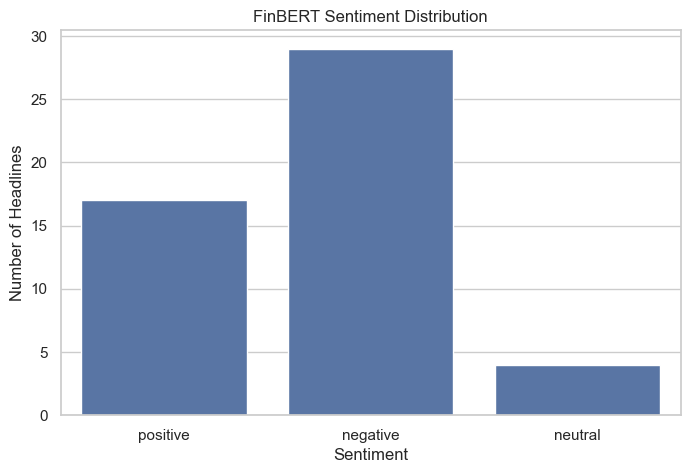

In [13]:
# Sentiment distribution
sentiment_counts = (
    nlp_df["FinBERT_Sentiment"]
    .value_counts()
    .reindex(["positive", "negative", "neutral"], fill_value=0)
)

print("FinBERT Sentiment Distribution:")
display(sentiment_counts.to_frame("Number_of_Headlines"))

# Confidence statistics
print("\nConfidence Statistics:")
display(
    nlp_df.groupby("FinBERT_Sentiment")["FinBERT_Confidence"]
    .agg(["count", "mean", "min", "max"])
    .round(4)
)

# Visualize sentiment distribution
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("FinBERT Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Headlines")
plt.show()

In [14]:
# Get probability distribution for all three sentiment classes
all_sentiment_scores = finbert(
    nlp_df["Headline"].tolist(),
    batch_size=8,
    top_k=None
)

# Extract probabilities
probability_df = pd.DataFrame([
    {item["label"]: item["score"] for item in result}
    for result in all_sentiment_scores
])

# Add probabilities to NLP dataset
nlp_df["Positive_Probability"] = probability_df["positive"].values
nlp_df["Negative_Probability"] = probability_df["negative"].values
nlp_df["Neutral_Probability"] = probability_df["neutral"].values

# Calculate normalized sentiment entropy
probabilities = probability_df[["positive", "negative", "neutral"]].values

entropy = -np.sum(
    probabilities * np.log(probabilities + 1e-12),
    axis=1
)

nlp_df["Sentiment_Entropy"] = entropy / np.log(3)

display(
    nlp_df[
        [
            "Headline",
            "FinBERT_Sentiment",
            "FinBERT_Confidence",
            "Sentiment_Entropy"
        ]
    ].head(15)
)

,Headline,FinBERT_Sentiment,FinBERT_Confidence,Sentiment_Entropy
0,Nikkei 225 index benefits from a weaker yen,negative,0.8458,0.4458
1,Government subsidy program gives a lift to the agriculture sector,positive,0.9178,0.2997
2,New housing data release shows a slowdown in market activity,negative,0.9707,0.1371
3,Massive stock buyback program announced by a consumer goods company,neutral,0.6851,0.6725
4,Government spending bill is expected to stimulate the economy,positive,0.9137,0.3049
5,Central bank maintains status quo on interest rates,neutral,0.9172,0.3122
6,Tech Giant's New Product Launch Sparks Sector-Wide Gains,positive,0.8705,0.4317
7,A massive data breach sends a tech company's stock tumbling,negative,0.8905,0.3677
8,Market sentiment turns positive on vaccine trial results,positive,0.9377,0.2501
9,"Global trade talks collapse, causing market turmoil",negative,0.9265,0.2701


Top 5 Most Uncertain Headlines:


,Headline,FinBERT_Sentiment,FinBERT_Confidence,Sentiment_Entropy
45,Central Bank's dovish tone hints at future rate cuts,negative,0.4339,0.9576
12,Market braces for a major policy announcement from the EU,neutral,0.5538,0.8818
41,Energy company's dividend hike excites shareholders,positive,0.5532,0.7937
34,Central Bank Governor signals potential shift in policy,negative,0.6530,0.7845
44,Pharmaceutical company's drug approval drives stock upward,negative,0.6627,0.7781


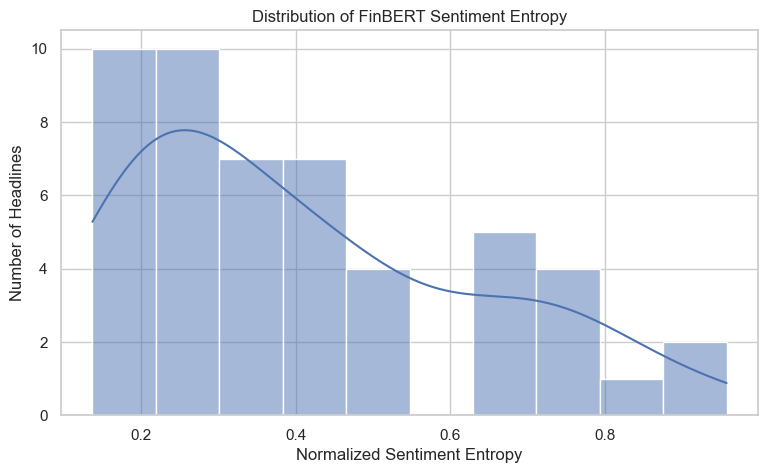

In [15]:
# Sort headlines by entropy
uncertain_headlines = nlp_df.sort_values(
    "Sentiment_Entropy",
    ascending=False
)

print("Top 5 Most Uncertain Headlines:")
display(
    uncertain_headlines[
        [
            "Headline",
            "FinBERT_Sentiment",
            "FinBERT_Confidence",
            "Sentiment_Entropy"
        ]
    ].head(5)
)

# Entropy distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    nlp_df["Sentiment_Entropy"],
    bins=10,
    kde=True
)

plt.title("Distribution of FinBERT Sentiment Entropy")
plt.xlabel("Normalized Sentiment Entropy")
plt.ylabel("Number of Headlines")

plt.show()

In [16]:
# Select all FinBERT output columns
finbert_output = nlp_df[
    [
        "Headline",
        "FinBERT_Sentiment",
        "FinBERT_Confidence",
        "Positive_Probability",
        "Negative_Probability",
        "Neutral_Probability",
        "Sentiment_Entropy"
    ]
].copy()

# Save results
finbert_output.to_csv(
    OUTPUT_DIR / "finbert_sentiment_results.csv",
    index=False
)

print("FinBERT results saved successfully!")
print("Shape:", finbert_output.shape)
print("File: finbert_sentiment_results.csv")

FinBERT results saved successfully!
Shape: (50, 7)
File: finbert_sentiment_results.csv


In [17]:
pip install sentence-transformers

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 760.7/760.7 kB 9.2 MB/s  0:00:00
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)

  Attempting uninstall: idna

    Found existing installation: idna 3.11

    Uninstalling idna-3.11:

      Successfully uninstalled idna-3.11

   ---------------------------------------- 0/3 [idna]
  Attempting uninstall: click
   ---------------------------------------- 0/3 [idna]
    Found existing installation: click 8.2.1
   ---------------------------------------- 0/3 [idna]
    Uninstalling click-8.2.1:
   ---------------------------------------- 0/3 [idna]
   ------------- -------------------------- 1/3 [click]
      Successfully uninstalled click-8.2.1
   ------------- -------------------------- 1/3 [click]
   --

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.0 which is incompatible.
aext-project-filebrowser-server 4.20.0 requires watchdog<5,>=4.0.1, but you have watchdog 6.0.0 which is incompatible.
python-lsp-server 1.13.1 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.0 which is incompatible.
spyder 6.1.0 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.0 which is incompatible.


In [18]:
from sentence_transformers import SentenceTransformer

print("Sentence Transformers imported successfully!")

Sentence Transformers imported successfully!


In [19]:
# Load pretrained MiniLM model

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("MiniLM model loaded successfully!")
print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\Victus\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Victus\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

MiniLM model loaded successfully!
Embedding dimension: 384


C:\Users\Victus\AppData\Local\Temp\ipykernel_5840\1135060360.py:8: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())


In [20]:
# Extract headline text
headlines = nlp_df["Headline"].tolist()

# Generate embeddings
embeddings = embedding_model.encode(
    headlines,
    batch_size=16,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embeddings generated successfully!")
print("Embedding shape:", embeddings.shape)
print("Data type:", embeddings.dtype)

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Embeddings generated successfully!
Embedding shape: (50, 384)
Data type: float32


In [21]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate pairwise cosine similarity
similarity_matrix = cosine_similarity(embeddings)

print("Similarity matrix shape:", similarity_matrix.shape)

# Find the most similar headline pairs
similarity_pairs = []

for i in range(len(headlines)):
    for j in range(i + 1, len(headlines)):
        similarity_pairs.append({
            "Headline_1": headlines[i],
            "Headline_2": headlines[j],
            "Similarity": similarity_matrix[i, j]
        })

similarity_df = pd.DataFrame(similarity_pairs)

# Display top 10 similar pairs
top_similar_pairs = similarity_df.sort_values(
    "Similarity",
    ascending=False
).head(10)

display(top_similar_pairs)

Similarity matrix shape: (50, 50)


,Headline_1,Headline_2,Similarity
1115,Central Bank Governor signals potential shift in policy,Central Bank's dovish tone hints at future rate cuts,0.5731
981,Retail sales report surpasses all forecasts,E-commerce earnings report beats all analyst expectations,0.5531
274,Central bank maintains status quo on interest rates,Central Bank's dovish tone hints at future rate cuts,0.5391
503,Supply chain issues impact manufacturing sector earnings,Semiconductor shortages weigh heavily on tech sector profits,0.5316
263,Central bank maintains status quo on interest rates,Central Bank Governor signals potential shift in policy,0.5283
877,Quarterly report shows surprising losses for retail giants,Retail sales report surpasses all forecasts,0.5264
708,Mining company stock surges on commodity price boom,Gold prices surge as investors flee riskier assets,0.5160
509,Supply chain issues impact manufacturing sector earnings,E-commerce earnings report beats all analyst expectations,0.4910
1112,Central Bank Governor signals potential shift in policy,Government policy shift boosts renewable energy sector,0.4887
51,Government subsidy program gives a lift to the agriculture sector,Government spending bill is expected to stimulate the economy,0.4884


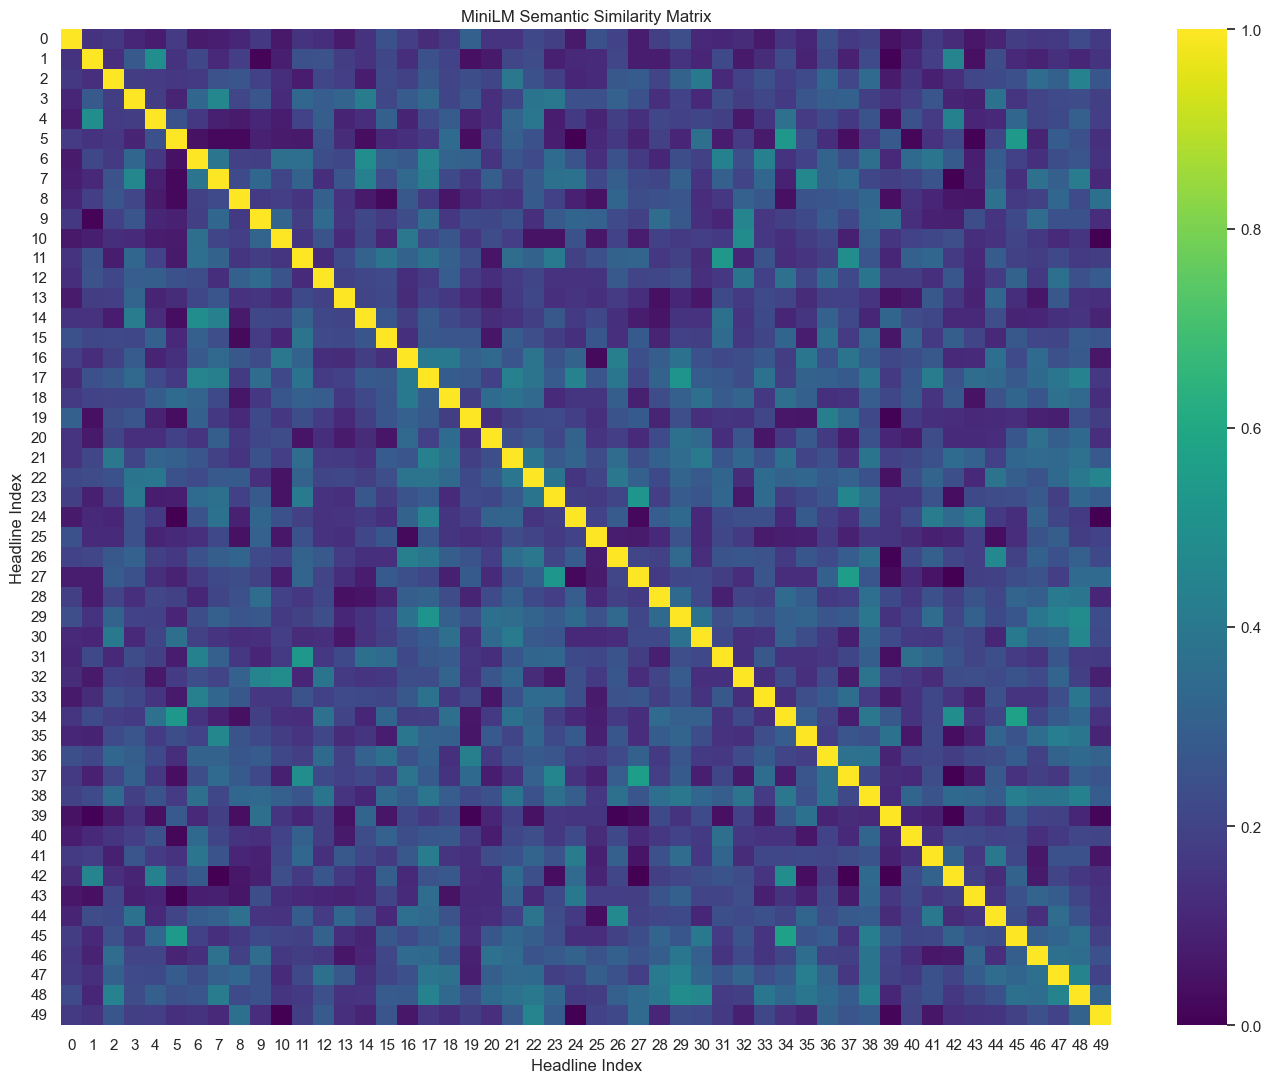

In [22]:
plt.figure(figsize=(14, 11))

sns.heatmap(
    similarity_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.title("MiniLM Semantic Similarity Matrix")
plt.xlabel("Headline Index")
plt.ylabel("Headline Index")

plt.tight_layout()
plt.show()

In [23]:
# Save MiniLM embeddings
np.save(
    OUTPUT_DIR / "minilm_embeddings.npy",
    embeddings
)

# Save similarity matrix
np.save(
    OUTPUT_DIR / "minilm_similarity_matrix.npy",
    similarity_matrix
)

# Save headline-to-embedding mapping
embedding_df = pd.DataFrame({
    "Headline_ID": range(len(headlines)),
    "Headline": headlines
})

embedding_df.to_csv(
    OUTPUT_DIR / "minilm_headline_mapping.csv",
    index=False
)

print("MiniLM outputs saved successfully!")
print("Embedding shape:", embeddings.shape)
print("Similarity matrix shape:", similarity_matrix.shape)

MiniLM outputs saved successfully!
Embedding shape: (50, 384)
Similarity matrix shape: (50, 50)


In [24]:
pip install spacy

   ---------------------------------------- 0.0/15.2 MB ? eta -:--:--
   ------ --------------------------------- 2.4/15.2 MB 12.0 MB/s eta 0:00:02
   ---------------------- ----------------- 8.4/15.2 MB 24.7 MB/s eta 0:00:01
   ------------------------------- -------- 12.1/15.2 MB 19.9 MB/s eta 0:00:01
   ------------------------------------- -- 14.2/15.2 MB 17.3 MB/s eta 0:00:01
   -------------------------------------- - 14.7/15.2 MB 17.7 MB/s eta 0:00:01
   ---------------------------------------- 15.2/15.2 MB 13.2 MB/s  0:00:01
   ---------------------------------------- 0.0/673.9 kB ? eta -:--:--
   ---------------------------------------- 673.9/673.9 kB 13.1 MB/s  0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 29.0 MB/s  0:00:00
   ---------------------------------------- 0.0/6.2 MB ? eta -:--:--
   -------------------- ------------------- 3.1/6.2 MB 23.1 MB/s eta 0:00:01
   --------------------

In [25]:
import spacy

print("spaCy version:", spacy.__version__)
print("spaCy imported successfully!")

spaCy version: 3.8.18
spaCy imported successfully!


In [28]:
# Load English language model
nlp = spacy.load("en_core_web_sm")

print("spaCy English model loaded successfully!")
print("Pipeline components:", nlp.pipe_names)

spaCy English model loaded successfully!
Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [29]:
# Apply spaCy NER to all headlines

ner_results = []

for headline in headlines:
    doc = nlp(headline)

    entities = [
        {
            "Entity": ent.text,
            "Entity_Label": ent.label_
        }
        for ent in doc.ents
    ]

    ner_results.append({
        "Headline": headline,
        "Entities": entities
    })

ner_df = pd.DataFrame(ner_results)

display(ner_df.head(15))

,Headline,Entities
0,Nikkei 225 index benefits from a weaker yen,"[{'Entity': '225', 'Entity_Label': 'CARDINAL'}]"
1,Government subsidy program gives a lift to the agriculture sector,[]
2,New housing data release shows a slowdown in market activity,[]
3,Massive stock buyback program announced by a consumer goods company,[]
4,Government spending bill is expected to stimulate the economy,[]
5,Central bank maintains status quo on interest rates,[]
6,Tech Giant's New Product Launch Sparks Sector-Wide Gains,[]
7,A massive data breach sends a tech company's stock tumbling,[]
8,Market sentiment turns positive on vaccine trial results,[]
9,"Global trade talks collapse, causing market turmoil",[]


In [30]:
from collections import Counter

# Flatten all extracted entities
all_entities = []

for result in ner_results:
    for entity in result["Entities"]:
        all_entities.append({
            "Entity": entity["Entity"],
            "Entity_Label": entity["Entity_Label"]
        })

entities_df = pd.DataFrame(all_entities)

print("Total entities extracted:", len(entities_df))

if not entities_df.empty:

    print("\nEntity Type Distribution:")
    display(
        entities_df["Entity_Label"]
        .value_counts()
        .to_frame("Count")
    )

    print("\nMost Frequently Extracted Entities:")
    display(
        entities_df["Entity"]
        .value_counts()
        .head(15)
        .to_frame("Frequency")
    )

else:
    print("No entities were detected.")

Total entities extracted: 22

Entity Type Distribution:


,Count
Entity_Label,
ORG,13
CARDINAL,4
DATE,2
GPE,2
MONEY,1



Most Frequently Extracted Entities:


,Frequency
Entity,
225,1
Defense,1
EU,1
multi-billion dollar,1
PMI,1
200,1
Utilities,1
Consumer Discretionary,1
Quarterly,1


In [31]:
# Define useful entity categories
relevant_labels = ["ORG", "GPE", "PERSON", "LOC"]

filtered_ner_results = []

for result in ner_results:

    relevant_entities = [
        entity for entity in result["Entities"]
        if entity["Entity_Label"] in relevant_labels
    ]

    filtered_ner_results.append({
        "Headline": result["Headline"],
        "Entities": relevant_entities,
        "Entity_Count": len(relevant_entities)
    })

filtered_ner_df = pd.DataFrame(filtered_ner_results)

print("Total headlines:", len(filtered_ner_df))
print(
    "Headlines containing relevant entities:",
    (filtered_ner_df["Entity_Count"] > 0).sum()
)

display(
    filtered_ner_df[filtered_ner_df["Entity_Count"] > 0]
)

Total headlines: 50
Headlines containing relevant entities: 13


,Headline,Entities,Entity_Count
10,Aerospace and Defense sector sees rally amid geopolitical tensions,"[{'Entity': 'Defense', 'Entity_Label': 'ORG'}]",1
12,Market braces for a major policy announcement from the EU,"[{'Entity': 'EU', 'Entity_Label': 'ORG'}]",1
15,Manufacturing PMI data signals economic expansion,"[{'Entity': 'PMI', 'Entity_Label': 'ORG'}]",1
21,Utilities sector remains stable during market fluctuations,"[{'Entity': 'Utilities', 'Entity_Label': 'ORG'}]",1
22,Consumer Discretionary stocks outperform as spending increases,"[{'Entity': 'Consumer Discretionary', 'Entity_Label': 'ORG'}]",1
25,China's Shanghai Composite falls after new trade restrictions,"[{'Entity': 'China', 'Entity_Label': 'GPE'}, {'Entity': 'Shanghai Composite', 'Entity_Label': 'ORG'}]",2
26,Healthcare stocks gain on robust demand and strong outlook,"[{'Entity': 'Healthcare', 'Entity_Label': 'ORG'}]",1
28,Federal Reserve Chairman's speech causes market volatility,"[{'Entity': 'Federal Reserve', 'Entity_Label': 'ORG'}]",1
33,Media and Entertainment companies report a surge in streaming revenue,"[{'Entity': 'Media', 'Entity_Label': 'ORG'}]",1
34,Central Bank Governor signals potential shift in policy,"[{'Entity': 'Central Bank', 'Entity_Label': 'ORG'}]",1


In [32]:
# Export raw NER results
raw_ner_rows = []

for result in ner_results:
    for entity in result["Entities"]:
        raw_ner_rows.append({
            "Headline": result["Headline"],
            "Entity": entity["Entity"],
            "Entity_Label": entity["Entity_Label"]
        })

raw_ner_df = pd.DataFrame(raw_ner_rows)

# Export filtered NER results
filtered_ner_rows = []

for result in filtered_ner_results:
    for entity in result["Entities"]:
        filtered_ner_rows.append({
            "Headline": result["Headline"],
            "Entity": entity["Entity"],
            "Entity_Label": entity["Entity_Label"]
        })

filtered_entity_df = pd.DataFrame(filtered_ner_rows)

# Save both files
raw_ner_df.to_csv(
    OUTPUT_DIR / "spacy_raw_entities.csv",
    index=False
)

filtered_entity_df.to_csv(
    OUTPUT_DIR / "spacy_filtered_entities.csv",
    index=False
)

print("NER results exported successfully!")
print("Raw entities:", raw_ner_df.shape)
print("Filtered entities:", filtered_entity_df.shape)

NER results exported successfully!
Raw entities: (22, 3)
Filtered entities: (15, 3)


In [33]:
pip install bertopic

   ---------------------------------------- 0.0/1.9 MB ? eta -:--:--
   --------------------- ------------------ 1.0/1.9 MB 18.1 MB/s eta 0:00:01
   --------------------- ------------------ 1.0/1.9 MB 18.1 MB/s eta 0:00:01
   --------------------- ------------------ 1.0/1.9 MB 18.1 MB/s eta 0:00:01
   --------------------- ------------------ 1.0/1.9 MB 18.1 MB/s eta 0:00:01
   --------------------- ------------------ 1.0/1.9 MB 18.1 MB/s eta 0:00:01
   --------------------- ------------------ 1.0/1.9 MB 18.1 MB/s eta 0:00:01
   ---------------------------------------- 1.9/1.9 MB 1.2 MB/s  0:00:01

   ---------------------------------------- 0/4 [pynndescent]
   ---------- ----------------------------- 1/4 [hdbscan]
   ---------- ----------------------------- 1/4 [hdbscan]
   ---------- ----------------------------- 1/4 [hdbscan]
   -------------------- ------------------- 2/4 [umap-learn]
   ------------------------------ --------- 3/4 [bertopic]
   ------------------------------ -----

In [34]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN

print("BERTopic, UMAP and HDBSCAN imported successfully!")

BERTopic, UMAP and HDBSCAN imported successfully!


In [35]:
# Configure UMAP
umap_model = UMAP(
    n_neighbors=5,
    n_components=2,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

# Configure HDBSCAN
hdbscan_model = HDBSCAN(
    min_cluster_size=4,
    min_samples=2,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

print("UMAP configuration ready!")
print("HDBSCAN configuration ready!")

UMAP configuration ready!
HDBSCAN configuration ready!


In [36]:
# Initialise BERTopic
topic_model = BERTopic(
    embedding_model=None,  # Reuse existing MiniLM embeddings
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    min_topic_size=4,
    verbose=True
)

# Fit BERTopic using existing embeddings
topics, probabilities = topic_model.fit_transform(
    headlines,
    embeddings
)

print("\nBERTopic training completed!")
print("Number of unique topics:", len(set(topics)) - (1 if -1 in topics else 0))
print("Number of noise points:", topics.count(-1))

2026-10-30 13:20:36,466 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-30 13:20:56,160 - BERTopic - Dimensionality - Completed ✓
2026-10-30 13:20:56,163 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-30 13:20:56,182 - BERTopic - Cluster - Completed ✓
2026-10-30 13:20:56,186 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-30 13:20:56,215 - BERTopic - Representation - Completed ✓



BERTopic training completed!
Number of unique topics: 6
Number of noise points: 7


In [37]:
# Display topic information
topic_info = topic_model.get_topic_info()

print("BERTopic Topic Information:")
display(topic_info)

BERTopic Topic Information:


,Topic,Count,Name,Representation,Representative_Docs
0,-1,7,-1_central_government_bank_banks,"[central, government, bank, banks, shift, the, policy, to, sector, boosts]","[Central Bank's dovish tone hints at future rate cuts, Government subsidy program gives a lift to the agriculture sector, Central Bank Governor si..."
1,0,11,0_market_as_investors_shows,"[market, as, investors, shows, data, in, new, sector, activity, bond]","[Bond yields tumble as investors seek safe havens, Real Estate sector shows signs of overheating as interest rates fall, New housing data release ..."
2,1,8,1_report_earnings_retail_manufacturing,"[report, earnings, retail, manufacturing, all, from, data, 100, 200, boost]","[Quarterly report shows surprising losses for retail giants, Retail sales report surpasses all forecasts, E-commerce earnings report beats all ana..."
3,2,8,2_tech_massive_major_stock,"[tech, massive, major, stock, in, acquires, costs, companies, by, goods]","[Major technology firm acquires a smaller rival in a multi-billion dollar deal, Massive stock buyback program announced by a consumer goods compan..."
4,3,6,3_consumer_stocks_on_confidence,"[consumer, stocks, on, confidence, discretionary, decade, drives, high, demand, approval]","[Consumer Discretionary stocks outperform as spending increases, Market sentiment turns positive on vaccine trial results, Healthcare stocks gain ..."
5,4,6,4_oil_financial_energy_stocks,"[oil, financial, energy, stocks, on, boom, surges, spill, commodity, capital]","[Mining company stock surges on commodity price boom, Major oil spill sends energy stocks plummeting, Financial services stocks rally on strong pr..."
6,5,4,5_geopolitical_trade_aerospace_ceasefire,"[geopolitical, trade, aerospace, ceasefire, causing, composite, defense, collapse, amid, chinas]","[Geopolitical ceasefire prompts a broad market recovery, Global trade talks collapse, causing market turmoil, Aerospace and Defense sector sees ra..."


In [38]:
# Get topic assignments for each headline
topic_assignments = topic_model.get_document_info(headlines)

# Display relevant columns
display(
    topic_assignments[
        ["Document", "Topic", "Name", "Probability"]
    ].sort_values(by="Topic")
)

,Document,Topic,Name,Probability
1,Government subsidy program gives a lift to the agriculture sector,-1,-1_central_government_bank_banks,0.0000
4,Government spending bill is expected to stimulate the economy,-1,-1_central_government_bank_banks,0.0000
5,Central bank maintains status quo on interest rates,-1,-1_central_government_bank_banks,0.0000
34,Central Bank Governor signals potential shift in policy,-1,-1_central_government_bank_banks,0.0000
42,Government policy shift boosts renewable energy sector,-1,-1_central_government_bank_banks,0.0000
45,Central Bank's dovish tone hints at future rate cuts,-1,-1_central_government_bank_banks,0.0000
39,Merger talks between two banks fall through,-1,-1_central_government_bank_banks,0.0000
2,New housing data release shows a slowdown in market activity,0,0_market_as_investors_shows,1.0000
29,Gold prices surge as investors flee riskier assets,0,0_market_as_investors_shows,1.0000
28,Federal Reserve Chairman's speech causes market volatility,0,0_market_as_investors_shows,0.8433


In [39]:
# Create a clean topic assignment dataset
bertopic_results = topic_assignments[
    ["Document", "Topic", "Name", "Probability"]
].copy()

# Rename columns
bertopic_results.rename(columns={
    "Document": "Headline",
    "Topic": "BERTopic_ID",
    "Name": "BERTopic_Name",
    "Probability": "Topic_Probability"
}, inplace=True)

# Save results
bertopic_results.to_csv(
    OUTPUT_DIR / "bertopic_topic_assignments.csv",
    index=False
)

# Save topic information
topic_info.to_csv(
    OUTPUT_DIR / "bertopic_topic_info.csv",
    index=False
)

print("BERTopic results saved successfully!")
print("Assignments shape:", bertopic_results.shape)
print("Topic information shape:", topic_info.shape)

display(bertopic_results.head())

BERTopic results saved successfully!
Assignments shape: (50, 4)
Topic information shape: (7, 5)


,Headline,BERTopic_ID,BERTopic_Name,Topic_Probability
0,Nikkei 225 index benefits from a weaker yen,1,1_report_earnings_retail_manufacturing,1.0000
1,Government subsidy program gives a lift to the agriculture sector,-1,-1_central_government_bank_banks,0.0000
2,New housing data release shows a slowdown in market activity,0,0_market_as_investors_shows,1.0000
3,Massive stock buyback program announced by a consumer goods company,2,2_tech_massive_major_stock,1.0000
4,Government spending bill is expected to stimulate the economy,-1,-1_central_government_bank_banks,0.0000


In [40]:
required_files = [
    "finbert_sentiment_results.csv",
    "spacy_filtered_entities.csv",
    "bertopic_topic_assignments.csv"
]

for file in required_files:
    file_path = OUTPUT_DIR / file
    print(f"{file}: {'Found' if file_path.exists() else 'Missing'}")

print("\nMiniLM embedding file:",
      (OUTPUT_DIR / "minilm_embeddings.npy").exists())

finbert_sentiment_results.csv: Found
spacy_filtered_entities.csv: Found
bertopic_topic_assignments.csv: Found

MiniLM embedding file: True


In [43]:
print("FinBERT columns:")
print(finbert_df.columns.tolist())

print("\nspaCy columns:")
print(spacy_df.columns.tolist())

print("\nBERTopic columns:")
print(bertopic_df.columns.tolist())

FinBERT columns:
['Headline', 'FinBERT_Sentiment', 'FinBERT_Confidence', 'Positive_Probability', 'Negative_Probability', 'Neutral_Probability', 'Sentiment_Entropy']

spaCy columns:
['Headline', 'Entity', 'Entity_Label']

BERTopic columns:
['Headline', 'BERTopic_ID', 'BERTopic_Name', 'Topic_Probability']


In [44]:
# Load individual NLP outputs
finbert_df = pd.read_csv(OUTPUT_DIR / "finbert_sentiment_results.csv")
spacy_df = pd.read_csv(OUTPUT_DIR / "spacy_filtered_entities.csv")
bertopic_df = pd.read_csv(OUTPUT_DIR / "bertopic_topic_assignments.csv")

# Group spaCy entities by headline
spacy_grouped = (
    spacy_df.groupby("Headline")
    .agg(
        NER_Entities=("Entity", lambda x: ", ".join(x)),
        NER_Entity_Labels=("Entity_Label", lambda x: ", ".join(x)),
        NER_Entity_Count=("Entity", "count")
    )
    .reset_index()
)

# Merge all NLP features
nlp_features = (
    finbert_df
    .merge(spacy_grouped, on="Headline", how="left")
    .merge(bertopic_df, on="Headline", how="left")
)

# Handle headlines with no extracted entities
nlp_features["NER_Entities"] = nlp_features["NER_Entities"].fillna("")
nlp_features["NER_Entity_Labels"] = nlp_features["NER_Entity_Labels"].fillna("")
nlp_features["NER_Entity_Count"] = (
    nlp_features["NER_Entity_Count"].fillna(0).astype(int)
)

# Save integrated dataset
nlp_features.to_csv(
    OUTPUT_DIR / "integrated_nlp_features.csv",
    index=False
)

print("Integrated NLP dataset created successfully!")
print("Dataset shape:", nlp_features.shape)
print("Unique headlines:", nlp_features["Headline"].nunique())

display(nlp_features.head())

Integrated NLP dataset created successfully!
Dataset shape: (50, 13)
Unique headlines: 50


,Headline,FinBERT_Sentiment,FinBERT_Confidence,Positive_Probability,Negative_Probability,Neutral_Probability,Sentiment_Entropy,NER_Entities,NER_Entity_Labels,NER_Entity_Count,BERTopic_ID,BERTopic_Name,Topic_Probability
0,Nikkei 225 index benefits from a weaker yen,negative,0.8458,0.1340,0.8458,0.0202,0.4458,,,0,1,1_report_earnings_retail_manufacturing,1.0000
1,Government subsidy program gives a lift to the agriculture sector,positive,0.9178,0.9178,0.0195,0.0627,0.2997,,,0,-1,-1_central_government_bank_banks,0.0000
2,New housing data release shows a slowdown in market activity,negative,0.9707,0.0093,0.9707,0.0200,0.1371,,,0,0,0_market_as_investors_shows,1.0000
3,Massive stock buyback program announced by a consumer goods company,neutral,0.6851,0.2770,0.0379,0.6851,0.6725,,,0,2,2_tech_massive_major_stock,1.0000
4,Government spending bill is expected to stimulate the economy,positive,0.9137,0.9137,0.0157,0.0706,0.3049,,,0,-1,-1_central_government_bank_banks,0.0000


In [45]:
# Final NLP dataset validation

print("Dataset Shape:", nlp_features.shape)
print("Unique Headlines:", nlp_features["Headline"].nunique())

print("\nDuplicate Headlines:",
      nlp_features["Headline"].duplicated().sum())

print("\nMissing Values:")
display(nlp_features.isnull().sum())

print("\nSentiment Distribution:")
display(nlp_features["FinBERT_Sentiment"].value_counts())

print("\nTopic Distribution:")
display(nlp_features["BERTopic_ID"].value_counts().sort_index())

# Check MiniLM embeddings
print("\nMiniLM Embedding Shape:", embeddings.shape)

# Final structural checks
assert nlp_features.shape[0] == 50
assert nlp_features["Headline"].nunique() == 50
assert nlp_features["Headline"].duplicated().sum() == 0
assert embeddings.shape == (50, 384)

print("\nAll structural validation checks passed!")

Dataset Shape: (50, 13)
Unique Headlines: 50

Duplicate Headlines: 0

Missing Values:


Headline                0
FinBERT_Sentiment       0
FinBERT_Confidence      0
Positive_Probability    0
Negative_Probability    0
Neutral_Probability     0
Sentiment_Entropy       0
NER_Entities            0
NER_Entity_Labels       0
NER_Entity_Count        0
BERTopic_ID             0
BERTopic_Name           0
Topic_Probability       0
dtype: int64


Sentiment Distribution:


FinBERT_Sentiment
negative    29
positive    17
neutral      4
Name: count, dtype: int64


Topic Distribution:


BERTopic_ID
-1     7
 0    11
 1     8
 2     8
 3     6
 4     6
 5     4
Name: count, dtype: int64


MiniLM Embedding Shape: (50, 384)

All structural validation checks passed!


## Conclusion

In this notebook, we developed an exploratory NLP pipeline to extract useful information from financial news headlines.

We used four major NLP techniques:

1. **FinBERT:** Used a pretrained financial language model to classify headlines into positive, negative and neutral sentiment. We also extracted sentiment probabilities, confidence scores and entropy.

2. **MiniLM:** Generated 384-dimensional sentence embeddings to represent headlines numerically. We also calculated cosine similarity to identify semantically related headlines.

3. **spaCy:** Applied Named Entity Recognition to identify organisations, locations and other relevant entities mentioned in financial headlines.

4. **BERTopic:** Applied UMAP and HDBSCAN to discover groups of semantically related headlines. The model identified six topics and classified seven headlines as noise.

Finally, we integrated the FinBERT, spaCy and BERTopic outputs into a single dataset containing 50 unique headlines and 13 columns. MiniLM embeddings were stored separately.

### Limitations

- The dataset contains only 50 unique headlines, which is insufficient for reliable generalisation.
- Several headlines have inconsistent or potentially incorrect entity classifications.
- FinBERT predictions have not been independently verified against human-labelled sentiment.
- BERTopic clusters are exploratory and contain some semantically mixed groups.
- The available dataset does not provide reliable ground-truth labels for supervised NLP evaluation.

### Future Scope

Future improvements can include collecting a larger dataset of authentic financial news, manually verifying event categories, improving financial entity extraction, and validating sentiment predictions against human annotations.

The extracted NLP features can subsequently be integrated with quantitative event-study results to investigate relationships between news sentiment, event categories and abnormal stock returns.

**Overall, this notebook establishes an exploratory NLP feature-extraction pipeline for the EventEcho project.**